In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.autograd import grad
import numpy as np
import matplotlib.pyplot as plt
from numpy import genfromtxt
torch.manual_seed(1234)
import os
import time

In [3]:
raw = np.genfromtxt(os.path.join("data", "iquitos_train.csv"),
                    delimiter=",")
t_data   = raw[0].astype(np.float32)
Itot_data = raw[1].astype(np.float32)
print(f"Data shape: t={len(t_data)}, Itot range [{Itot_data.min():.0f}, {Itot_data.max():.0f}]")


Data shape: t=80, Itot range [8, 946]


In [4]:
# Cell 1: FIXED - Imports, Data Load, Param Bounds, Model Definition, Inverse Training
# Parameter bounds [file:2]
param_bounds = {
    'lambda': (0.0, 0.6), 'betam': (0.0, 0.05), 'mum': (0.001, 0.016),
    'thetam': (0.01, 0.2), 'muh': (0.001, 0.0195), 'betah': (0.001, 0.055),
    'thetah': (0.01, 0.53), 'gammah': (0.05, 0.1)
}
calib_input_dim = 10

class CalibNet(nn.Module):
    def __init__(self, param_bounds):
        super().__init__()
        self.fc1 = nn.Linear(calib_input_dim, 64)
        self.fc2 = nn.Linear(64, 64)
        self.fc3 = nn.Linear(64, len(param_bounds))
        self.param_bounds = param_bounds
        self.param_names = list(param_bounds.keys())

    def forward(self, calib_input):
        x = F.gelu(self.fc1(calib_input))
        x = F.gelu(self.fc2(x))
        raw = self.fc3(x)
        params = {}
        for i, name in enumerate(self.param_names):
            lo, hi = self.param_bounds[name]
            p_tilda = raw[..., i]
            p = torch.tanh(p_tilda) * (hi - lo)/2 + (hi + lo)/2
            params[name] = p
        return params

class EmuNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(1, 20); self.fc2 = nn.Linear(20, 20); self.fc3 = nn.Linear(20, 20)
        self.fc4 = nn.Linear(20, 20); self.fc5 = nn.Linear(20, 20); self.fc6 = nn.Linear(20, 20)
        self.fc7 = nn.Linear(20, 20); self.fc8 = nn.Linear(20, 20); self.out = nn.Linear(20, 8)

    def forward(self, t_batch):
        x = F.gelu(self.fc1(t_batch)); x = F.gelu(self.fc2(x)); x = F.gelu(self.fc3(x))
        x = F.gelu(self.fc4(x)); x = F.gelu(self.fc5(x)); x = F.gelu(self.fc6(x))
        x = F.gelu(self.fc7(x)); x = F.gelu(self.fc8(x))
        return F.softplus(self.out(x))

class DengueDINN2(nn.Module):
    def __init__(self, t, Itot_data, param_bounds):
        super().__init__()
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.t = torch.tensor(t, dtype=torch.float32,
                              requires_grad=True, device=self.device)
        self.t_batch = self.t.reshape(-1, 1)
        self.Itot = torch.tensor(Itot_data, dtype=torch.float32,
                                     device=self.device)
        self.Itot_hat = torch.log1p(self.Itot)
        self.calib = CalibNet(param_bounds).to(self.device)
        self.emu   = EmuNet().to(self.device)
        self.params = list(self.calib.parameters()) + list(self.emu.parameters())
        self.optimizer = optim.Adam(
            self.params,
            lr=5e-4,
            betas=(0.9, 0.999),
            weight_decay=1e-5
        )
        self.scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer,
            mode='min',
            factor=0.7,
            patience=1000,
            min_lr=1e-7
        )
        self.losses = []


    def netf(self, calib_input):
        calib_input = calib_input.to(self.device)
        params = self.calib(calib_input)
        λ = params['lambda']; betam = params['betam']; mum = params['mum']; thetam = params['thetam']
        muh = params['muh']; betah = params['betah']; thetah = params['thetah']; gammah = params['gammah']
        dengue_hat = self.emu(self.t_batch)
        Hr_hat = dengue_hat[:, 0:1]; Hs_hat = dengue_hat[:, 1:2]; He_hat = dengue_hat[:, 2:3]
        Hi_hat = dengue_hat[:, 3:4]; Me_hat = dengue_hat[:, 4:5]; Ms_hat = dengue_hat[:, 5:6]
        Mi_hat = dengue_hat[:, 6:7]; Itot_hat_pred = dengue_hat[:, 7:8]
        # FIXED: Correct grad_outputs shape [N,1] matching output shape
        Hr_t = grad(Hr_hat.sum(), self.t, retain_graph=True, create_graph=True)[0]
        Hs_t = grad(Hs_hat.sum(), self.t, retain_graph=True, create_graph=True)[0]
        He_t = grad(He_hat.sum(), self.t, retain_graph=True, create_graph=True)[0]
        Hi_t = grad(Hi_hat.sum(), self.t, retain_graph=True, create_graph=True)[0]
        Me_t = grad(Me_hat.sum(), self.t, retain_graph=True, create_graph=True)[0]
        Ms_t = grad(Ms_hat.sum(), self.t, retain_graph=True, create_graph=True)[0]
        Mi_t = grad(Mi_hat.sum(), self.t, retain_graph=True, create_graph=True)[0]
        Itot_t = grad(Itot_hat_pred.sum(), self.t, retain_graph=True, create_graph=True)[0]
        # Unnormalize
        Hr = torch.expm1(Hr_hat.squeeze(1)); Hs = torch.expm1(Hs_hat.squeeze(1))
        He = torch.expm1(He_hat.squeeze(1)); Hi = torch.expm1(Hi_hat.squeeze(1))
        Me = torch.expm1(Me_hat.squeeze(1)); Ms = torch.expm1(Ms_hat.squeeze(1))
        Mi = torch.expm1(Mi_hat.squeeze(1)); Itot = torch.expm1(Itot_hat_pred.squeeze(1))
        H = torch.clamp(Hr + Hs + He + Hi, min=1e-8)
        M = torch.clamp(Me + Ms + Mi, min=1e-8)
        # Residuals
        f1_hat = Hr_t - (gammah * Hi - muh * Hr) / (1.0 + Hr)
        f2_hat = Hs_t - (muh * H - betah * Mi * Hs / M - muh * Hs) / (1.0 + Hs)
        f3_hat = He_t - (betah * Mi * Hs / M - thetah * He - muh * He) / (1.0 + He)
        f4_hat = Hi_t - (thetah * He - gammah * Hi - muh * Hi) / (1.0 + Hi)
        f5_hat = Me_t - (betam * Hi * Ms / H - thetam * Me - mum * Me) / (1.0 + Me)
        f6_hat = Ms_t - (λ - betam * Hi * Ms / H - mum * Ms) / (1.0 + Ms)
        f7_hat = Mi_t - (thetam * Me - mum * Mi) / (1.0 + Mi)
        f8_hat = Itot_t - (thetah * He) / (1.0 + Itot)
        return (f1_hat, f2_hat, f3_hat, f4_hat, f5_hat, f6_hat, f7_hat, f8_hat, Itot_hat_pred.squeeze(1))

    def train_loop(self, nepochs=2000):
        calib_input = torch.zeros(1, calib_input_dim)
        start_time = time.time() 
        self.loss_data_list = []
        self.loss_phys_list = []
        for epoch in range(nepochs):
            self.optimizer.zero_grad()
            f = self.netf(calib_input)
            loss_data = F.mse_loss(f[8], self.Itot_hat)
            loss_phys = sum(F.mse_loss(r, torch.zeros_like(r)) for r in f[:8])
            loss = loss_data + loss_phys
            loss.backward()
            self.optimizer.step()
            self.scheduler.step(loss.detach())
            self.losses.append(loss.item())
            self.loss_data_list.append(loss_data.item())
            self.loss_phys_list.append(loss_phys.item())
            if epoch % 200 == 0:
                print(f"Epoch {epoch}: Total loss: {loss.item():.2e}, data loss: {loss_data.item():.2e}, physic loss: {loss_phys.item():.2e}")
        end_time = time.time()
        runtime = end_time - start_time
        print(f"Training completed in {runtime:.2f} seconds ({runtime/60:.2f} minutes)")
        
        # Plot
        plt.figure(figsize=(10,6))
        plt.semilogy(self.losses, label='Total loss', linewidth=2)
        plt.semilogy(self.loss_data_list, label='Data loss', linewidth=2)
        plt.semilogy(self.loss_phys_list, label='Physics loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Training Losses')
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.show()
        print("Inverse training complete")

Epoch 0: Total loss: 2.44e+01, data loss: 2.44e+01, physic loss: 7.69e-02
Epoch 200: Total loss: 1.11e+00, data loss: 1.10e+00, physic loss: 9.48e-03
Epoch 400: Total loss: 1.86e-01, data loss: 1.78e-01, physic loss: 7.17e-03
Epoch 600: Total loss: 6.33e-02, data loss: 5.76e-02, physic loss: 5.72e-03
Epoch 800: Total loss: 4.71e-02, data loss: 4.19e-02, physic loss: 5.27e-03
Epoch 1000: Total loss: 3.63e-02, data loss: 3.12e-02, physic loss: 5.06e-03
Epoch 1200: Total loss: 2.45e-02, data loss: 1.87e-02, physic loss: 5.76e-03
Epoch 1400: Total loss: 1.73e-02, data loss: 1.08e-02, physic loss: 6.55e-03
Epoch 1600: Total loss: 1.22e-02, data loss: 5.58e-03, physic loss: 6.60e-03
Epoch 1800: Total loss: 9.95e-03, data loss: 3.70e-03, physic loss: 6.25e-03
Epoch 2000: Total loss: 9.73e-03, data loss: 3.48e-03, physic loss: 6.25e-03
Epoch 2200: Total loss: 8.94e-03, data loss: 2.55e-03, physic loss: 6.38e-03
Epoch 2400: Total loss: 8.76e-03, data loss: 2.30e-03, physic loss: 6.46e-03
Epoch 

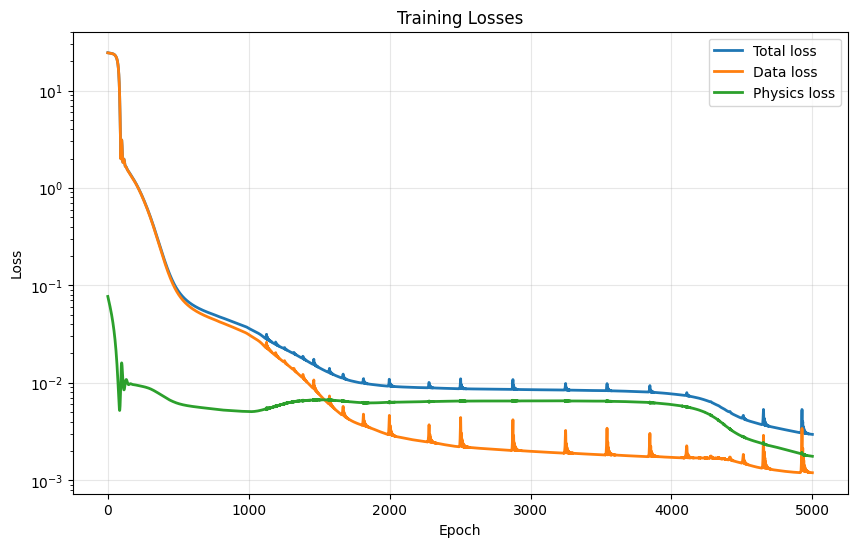

Inverse training complete


In [5]:
# Instantiate & Train
dinn2 = DengueDINN2(t_data, Itot_data, param_bounds)
dinn2.train_loop(5001)

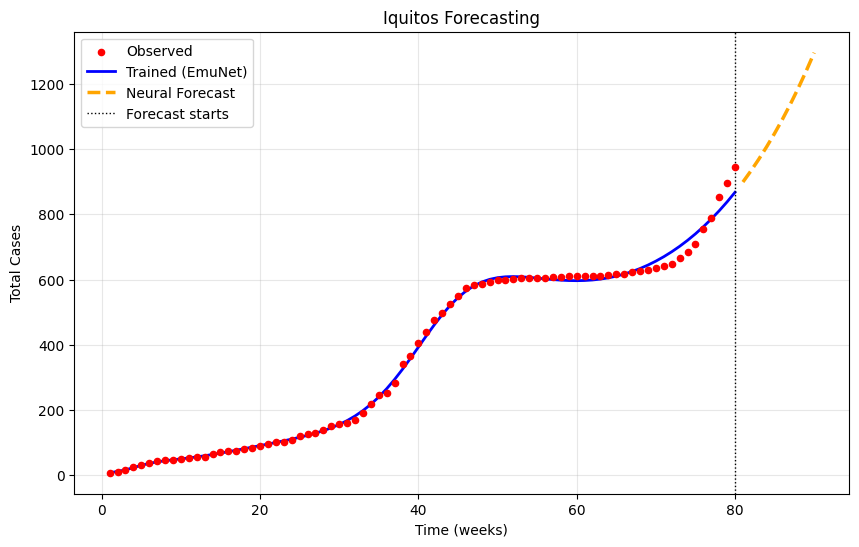

In [6]:
# Cell 2: Pure Neural Forecasting (EmuNet extrapolation)
forecast_weeks = 10
t_last = float(t_data[-1])
t_forecast = np.linspace(t_last, t_last + forecast_weeks, forecast_weeks + 1)[1:]
t_forecast_tensor = torch.tensor(t_forecast).float().reshape(-1, 1)

dinn2.eval()
with torch.no_grad():
    states_log_forecast = dinn2.emu(t_forecast_tensor)
    Itot_neural_forecast = torch.expm1(states_log_forecast[:, 7]).numpy()

# Plot
plt.figure(figsize=(10,6))
plt.scatter(t_data, Itot_data, s=20, color='red', label='Observed', zorder=5)
train_Itot = torch.expm1(dinn2.emu(dinn2.t_batch)[:, 7]).detach().numpy()
plt.plot(dinn2.t.detach().numpy(), train_Itot, 'b-', lw=2, label='Trained (EmuNet)')
plt.plot(t_forecast, Itot_neural_forecast, 'orange', ls='--', lw=2.5, label='Neural Forecast')
plt.axvline(t_last, color='k', ls=':', lw=1, label='Forecast starts')
plt.xlabel('Time (weeks)'); plt.ylabel('Total Cases'); plt.legend(); plt.grid(True, alpha=0.3)
plt.title('Iquitos Forecasting')
plt.show()
# print(f"Neural forecast final value: {Itot_neural_forecast[-1]:.1f}")


In [7]:
# Cell 3: Relative RMSE (NRMSE / std normalization) for Itot
import math

dengue_data = [t_data, Itot_data]  # weeks, cumulative Hi
with torch.no_grad():
    Itot_hat_pred = dinn2.emu(dinn2.t_batch)[:, 7]  # log1p from emu
    Itot_pred = torch.expm1(Itot_hat_pred).cpu().numpy()  # denormalize

Itot_total_loss = 0 
Itot_den = 0
for timestep in range(len(dengue_data[0])):
    Itot_value = dengue_data[1][timestep] - Itot_pred[timestep]
    Itot_total_loss += Itot_value**2
    Itot_den += (dengue_data[1][timestep])**2

Itot_total_loss = math.sqrt(Itot_total_loss / Itot_den)
print('Itot_total_loss (relative RMSE):', Itot_total_loss)


Itot_total_loss (relative RMSE): 0.03465044055328978
